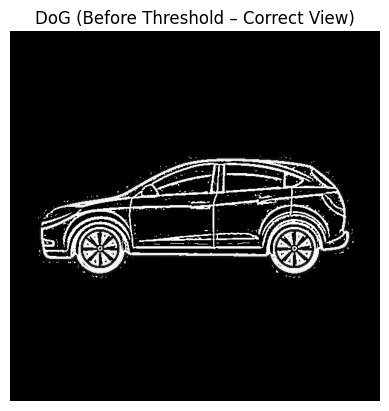

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('/kaggle/input/blobdetect/car.jpg', 0)

# DoG
g1 = cv2.GaussianBlur(img, (5,5), 0)
g2 = cv2.GaussianBlur(img, (9,9), 0)
dog = g1 - g2   # raw DoG (has + and - values)

# FIX for visualization
dog_abs = np.abs(dog)
dog_norm = cv2.normalize(dog_abs, None, 0, 255, cv2.NORM_MINMAX)
dog_norm = np.uint8(dog_norm)

# Show
plt.imshow(dog_norm, cmap='gray')
plt.title("DoG (Before Threshold – Correct View)")
plt.axis('off')
plt.show()

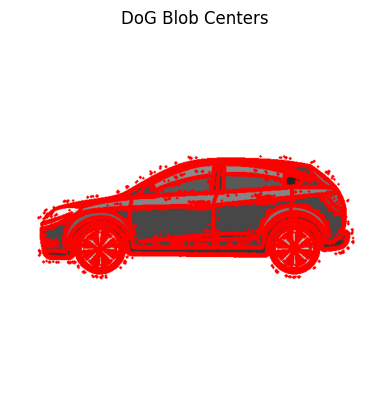

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread('/kaggle/input/blobdetect/car.jpg', 0)

# Two Gaussian blurs
g1 = cv2.GaussianBlur(img, (5,5), 0)
g2 = cv2.GaussianBlur(img, (9,9), 0)

# Difference of Gaussians
dog = g1 - g2

# Take absolute value and normalize
dog_abs = np.abs(dog)
dog_norm = cv2.normalize(dog_abs, None, 0, 255, cv2.NORM_MINMAX)
dog_norm = np.uint8(dog_norm)

# Threshold to find strong blobs
_, thresh = cv2.threshold(dog_norm, 50, 255, cv2.THRESH_BINARY)

# Find blob centers
keypoints = cv2.findNonZero(thresh)

# Convert original image to color
img_color = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

# Mark blob centers in red
for p in keypoints:
    x, y = p[0]
    cv2.circle(img_color, (x, y), 2, (0,0,255), -1)

# Show result
plt.imshow(cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("DoG Blob Centers")
plt.show()